# ДЗ2. Дополнительное задание: статистическое сравнение моделей

Курсовой проект ML/DLOps. Прогнозирование стоимости объявлений Airbnb.

Цель работы: определить, насколько убедительно различаются ошибки двух конфигураций Random Forest, исследованных в `03_mlflow.ipynb`. Для сравнения использую одинаковую тестовую выборку и парный кластерный bootstrap по `listing_id`. Основная метрика — MAE, дополнительная — RMSE.

## 1. Библиотеки и функции проекта

In [1]:
%pip install -q "boto3==1.43.18" "scikit-learn==1.8.0" matplotlib

In [2]:
import os
import sys
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit

In [3]:
PROJECT_URL = "https://github.com/kss4891-dev/mlops-airbnb-course.git"

if (Path.cwd() / "train.py").is_file():
    project_dir = Path.cwd()
elif (Path.cwd().parent / "train.py").is_file():
    project_dir = Path.cwd().parent
else:
    project_dir = Path.home() / "mlops-airbnb-course"
    if not (project_dir / "train.py").is_file():
        subprocess.run(
            ["git", "clone", "--depth", "1", PROJECT_URL, str(project_dir)],
            check=True,
        )

sys.path.insert(0, str(project_dir))
from train import make_pipeline, read_s3_data, split_data

print("Используем train.py из:", project_dir)

Используем train.py из: /root/mlops-airbnb-course


## 2. Загрузка данных и разделение выборки

Использую тот же источник S3 и функции подготовки данных, что в MLflow-эксперименте. Ключи доступа не сохраняю в ноутбуке.

In [4]:
KEY_NAMES = ("AWS_ACCESS_KEY_ID", "AWS_SECRET_ACCESS_KEY")

if not all(os.environ.get(key) for key in KEY_NAMES):
    try:
        from google.colab import userdata
    except ImportError:
        pass
    else:
        for key in KEY_NAMES:
            if not os.environ.get(key):
                value = userdata.get(key)
                if value:
                    os.environ[key] = value

if not all(os.environ.get(key) for key in KEY_NAMES):
    raise RuntimeError(
        "Для чтения S3 нужны AWS_ACCESS_KEY_ID и AWS_SECRET_ACCESS_KEY. "
        "Укажите их через Colab Secrets или переменные окружения."
    )

print("Ключи S3 доступны через переменные окружения (значения скрыты)")

Ключи S3 доступны через переменные окружения (значения скрыты)


In [5]:
df = read_s3_data()
X_train, X_test, y_train, y_test = split_data(df)

# Восстанавливаем идентификаторы групп из того же GroupShuffleSplit.
# Проверяем, что порядок строк действительно совпадает с split_data.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(df, groups=df["listing_id"]))
for idx, X_part, y_part in [(train_idx, X_train, y_train), (test_idx, X_test, y_test)]:
    pd.testing.assert_frame_equal(
        df.iloc[idx][X_part.columns].reset_index(drop=True),
        X_part.reset_index(drop=True), check_dtype=False
    )
    np.testing.assert_allclose(df.iloc[idx]["price"].to_numpy(dtype=float),
                               np.asarray(y_part, dtype=float))

groups_test = df.iloc[test_idx]["listing_id"].to_numpy()
assert not pd.isna(groups_test).any()
assert not set(df.iloc[train_idx]["listing_id"]) & set(groups_test)
print("Строк в train:", len(X_train))
print("Строк в test:", len(X_test))
print("Уникальных объявлений в test:", pd.Series(groups_test).nunique())

S3 data loaded: 20151 rows, 13 columns
Train: (16076, 10); test: (4075, 10); shared listings: 0
Строк в train: 16076
Строк в test: 4075
Уникальных объявлений в test: 1798


## 3. Сравниваемые модели

Первая конфигурация: 100 деревьев, максимальная глубина 15. Вторая: 150 деревьев, максимальная глубина 10. Остальные настройки и предобработка одинаковые. Обе модели повторно обучаются через `make_pipeline()` на одной обучающей выборке. Прогнозы строятся для одних и тех же тестовых строк.

In [6]:
configs = {
    "Baseline": {"n_estimators": 100, "max_depth": 15},
    "Variant": {"n_estimators": 150, "max_depth": 10},
}
predictions = {}
rows = []
y_true = np.asarray(y_test, dtype=float)
for name, params in configs.items():
    pipeline = make_pipeline()
    pipeline.set_params(model__n_estimators=params["n_estimators"],
                        model__max_depth=params["max_depth"],
                        model__random_state=42)
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    assert np.isfinite(pred).all()
    predictions[name] = pred
    rows.append({"Модель": name, **params,
                 "MAE": mean_absolute_error(y_true, pred),
                 "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
                 "R²": r2_score(y_true, pred)})
comparison = pd.DataFrame(rows).set_index("Модель")
display(comparison.round(4))

,n_estimators,max_depth,MAE,RMSE,R²
Модель,,,,,
Baseline,100,15,102.4813,360.7729,0.1583
Variant,150,10,105.5427,363.0433,0.1477


### Вывод

По результатам сравнения двух конфигураций Random Forest базовая модель показала лучшие результаты по всем рассматриваемым метрикам.

MAE базовой модели составила 102,48, а альтернативной модели — 105,54. Средняя абсолютная ошибка базовой модели оказалась ниже примерно на 2,9%.

Аналогичная картина наблюдается по RMSE: 360,77 у базовой модели против 363,04 у альтернативной. Значение R² также выше у базовой модели: 0,1583 против 0,1477.

Таким образом, увеличение количества деревьев со 100 до 150 при одновременном уменьшении максимальной глубины с 15 до 10 не привело к улучшению качества прогнозирования.

Однако наблюдаемые различия в метриках сами по себе не позволяют утверждать, что преимущество базовой модели является статистически значимым. Для проверки этого предположения далее будет проведено статистическое сравнение моделей с использованием bootstrap.

## 4. Статистические гипотезы

Обозначу разность ошибок как Δ = MAE(Variant) − MAE(Baseline).

H0: ожидаемая разность MAE равна нулю.

H1: ожидаемая разность MAE не равна нулю.

Уровень значимости 0,05. Положительная разность означает преимущество Baseline, отрицательная — Variant. Основной критерий — положение нуля относительно 95%-го bootstrap-интервала разности MAE.

Один `listing_id` может встречаться несколько раз, поэтому случайно выбираю объявления целиком с возвращением, сохраняя все их строки. Для обеих моделей в каждой итерации используется одна и та же bootstrap-выборка. Метрики по-прежнему рассчитываются по строкам, как в MLflow, а не как среднее по объявлениям с одинаковым весом.

In [7]:
errors = pd.DataFrame({
    "listing_id": groups_test,
    "abs_base": np.abs(y_true - predictions["Baseline"]),
    "abs_var": np.abs(y_true - predictions["Variant"]),
    "sq_base": (y_true - predictions["Baseline"]) ** 2,
    "sq_var": (y_true - predictions["Variant"]) ** 2,
    "n": 1,
})
cluster = errors.groupby("listing_id", sort=False).sum()
values = cluster[["abs_base", "abs_var", "sq_base", "sq_var", "n"]].to_numpy(float)
n_groups = len(values)
assert n_groups > 1
B = 10000
rng = np.random.default_rng(42)
boot_mae = np.empty(B)
boot_rmse = np.empty(B)
for i in range(B):
    sampled = rng.integers(0, n_groups, size=n_groups)
    a, b, s1, s2, count = values[sampled].sum(axis=0)
    boot_mae[i] = (b - a) / count
    boot_rmse[i] = np.sqrt(s2 / count) - np.sqrt(s1 / count)

observed_mae = comparison.loc["Variant", "MAE"] - comparison.loc["Baseline", "MAE"]
observed_rmse = comparison.loc["Variant", "RMSE"] - comparison.loc["Baseline", "RMSE"]
ci_mae = np.quantile(boot_mae, [0.025, 0.975])
ci_rmse = np.quantile(boot_rmse, [0.025, 0.975])
result = pd.DataFrame({
    "Метрика": ["MAE", "RMSE"],
    "Разность (Variant - Baseline)": [observed_mae, observed_rmse],
    "Нижняя граница 95% ДИ": [ci_mae[0], ci_rmse[0]],
    "Верхняя граница 95% ДИ": [ci_mae[1], ci_rmse[1]],
})
display(result.round(4))

,Метрика,Разность (Variant - Baseline),Нижняя граница 95% ДИ,Верхняя граница 95% ДИ
0,MAE,3.0614,1.6498,4.5305
1,RMSE,2.2703,0.3235,5.3624


### Вывод

Для оценки статистической значимости различий между моделями был применён парный кластерный bootstrap с 10 000 итераций. Повторные наблюдения одного объявления учитывались совместно при формировании bootstrap-выборок.

Разность MAE между альтернативной и базовой моделями составила 3,0614, а 95%-й доверительный интервал — [1,6498; 4,5305].

Поскольку доверительный интервал не содержит ноль и обе его границы положительны, нулевая гипотеза об отсутствии различий по MAE отвергается на уровне значимости 0,05.

Для RMSE получена аналогичная картина. Разность ошибок составила 2,2703, а 95%-й доверительный интервал — [0,3235; 5,3624]. Данный интервал также не содержит ноль.

Таким образом, результаты статистического исследования подтверждают преимущество базовой конфигурации Random Forest на исследуемой тестовой выборке. Наблюдаемое снижение ошибки MAE является статистически значимым.

При этом статистическая значимость различий не обязательно означает их высокую практическую значимость. Несмотря на преимущество базовой модели, абсолютное улучшение MAE составляет около 3 единиц цены.

## 5. Распределение bootstrap-разностей

График показывает неопределённость оценки разницы MAE на тестовых объявлениях.

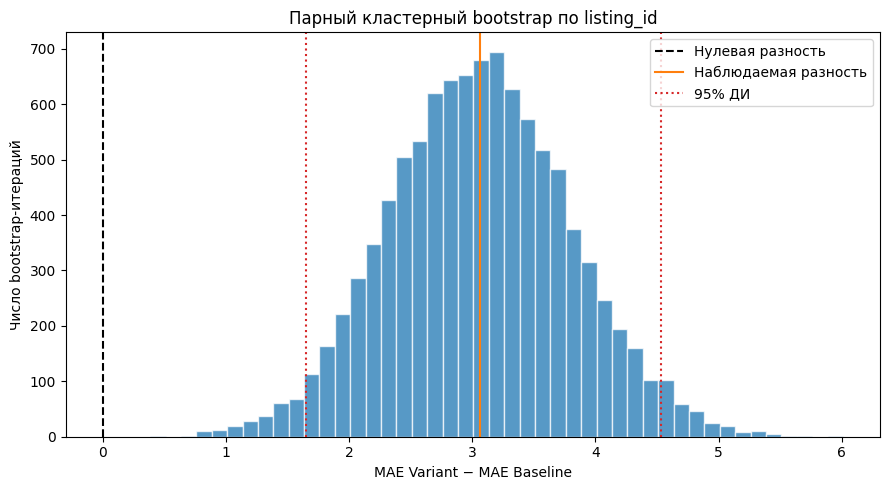

In [8]:
plt.figure(figsize=(9, 5))
plt.hist(boot_mae, bins=45, alpha=0.75, edgecolor="white")
plt.axvline(0, color="black", linestyle="--", label="Нулевая разность")
plt.axvline(observed_mae, color="tab:orange", label="Наблюдаемая разность")
plt.axvline(ci_mae[0], color="tab:red", linestyle=":", label="95% ДИ")
plt.axvline(ci_mae[1], color="tab:red", linestyle=":")
plt.xlabel("MAE Variant − MAE Baseline")
plt.ylabel("Число bootstrap-итераций")
plt.title("Парный кластерный bootstrap по listing_id")
plt.legend()
plt.tight_layout()
plt.show()

### Вывод

Полученное bootstrap-распределение разности MAE имеет приблизительно симметричную колоколообразную форму и сосредоточено вблизи наблюдаемой разности 3,06.

Границы 95%-го доверительного интервала находятся правее нулевого значения. Это визуально подтверждает статистически значимое преимущество базовой модели по MAE.

Таким образом, результаты графического анализа согласуются с ранее полученными числовыми оценками и свидетельствуют о более низкой средней абсолютной ошибке базовой конфигурации Random Forest.

## 6. Проверка гипотезы и вывод

Вывод формируется по фактически рассчитанным метрикам и доверительным интервалам.

In [9]:
base = comparison.loc["Baseline", "MAE"]
variant = comparison.loc["Variant", "MAE"]
lo, hi = ci_mae
if lo > 0:
    decision = "Нулевая гипотеза отвергается на уровне 0,05 по bootstrap-интервалу. Baseline имеет меньшую MAE."
elif hi < 0:
    decision = "Нулевая гипотеза отвергается на уровне 0,05 по bootstrap-интервалу. Variant имеет меньшую MAE."
else:
    decision = "Нулевая гипотеза не отвергается: интервал включает ноль. Доказательств различия MAE недостаточно. Это не означает, что модели эквивалентны."
relative = 100 * observed_mae / base if base else np.nan
winner = "Baseline" if base < variant else "Variant" if variant < base else "обе модели одинаковы"
display(Markdown(f"""На тестовой выборке MAE первой модели составила {base:.2f}, второй — {variant:.2f}. Разность MAE (Variant минус Baseline) равна {observed_mae:.2f}, или {relative:+.2f}% относительно Baseline. По точечной оценке MAE: {winner}.

95%-й доверительный интервал разности MAE: [{lo:.2f}; {hi:.2f}]. {decision}

Разность RMSE составляет {observed_rmse:.2f}, 95%-й доверительный интервал: [{ci_rmse[0]:.2f}; {ci_rmse[1]:.2f}]. RMSE рассматриваю как дополнительную описательную метрику, а решение по основной гипотезе принимаю по MAE."""))

На тестовой выборке MAE первой модели составила 102.48, второй — 105.54. Разность MAE (Variant минус Baseline) равна 3.06, или +2.99% относительно Baseline. По точечной оценке MAE: Baseline.

95%-й доверительный интервал разности MAE: [1.65; 4.53]. Нулевая гипотеза отвергается на уровне 0,05 по bootstrap-интервалу. Baseline имеет меньшую MAE.

Разность RMSE составляет 2.27, 95%-й доверительный интервал: [0.32; 5.36]. RMSE рассматриваю как дополнительную описательную метрику, а решение по основной гипотезе принимаю по MAE.

## 7. Ограничения исследования

Bootstrap оценивает неопределённость разности ошибок двух фиксированных обученных моделей на тестовых объявлениях. Он не учитывает вариативность повторного обучения на других обучающих выборках и предполагает независимость между объявлениями. Одновременно изменены два гиперпараметра, поэтому нельзя выделить эффект каждого из них. Поскольку эти конфигурации уже сравнивались на данной тестовой выборке в MLflow, исследование носит разведочный характер; для независимого подтверждения полезна новая отложенная выборка. Статистически значимая разница не обязательно практически важна: это зависит от требований к точности прогноза цены.

## Итоговый вывод

В рамках дополнительного задания было проведено статистическое сравнение двух конфигураций Random Forest с использованием парного кластерного bootstrap.

Полученные результаты показали, что базовая модель со 100 деревьями и максимальной глубиной 15 превосходит альтернативную конфигурацию по всем рассматриваемым метрикам качества. Различие по основной метрике MAE является статистически значимым на уровне 0,05.

На основании проведённого исследования для дальнейшего использования в проекте целесообразно сохранить базовую конфигурацию модели. При этом для независимого подтверждения полученных результатов желательно провести дополнительную оценку на новой тестовой выборке.